# TP17 — Classifieur d’images NutriScope
Construire un CNN simple, le comparer à un modèle par transfert sur la même validation, puis évaluer le modèle choisi une seule fois sur le test.

Tu complètes les TODO progressivement. Les fonctions encore incomplètes lèvent volontairement `NotImplementedError` : ne pas lancer « Tout exécuter ».

**Référence :** README.md du TP17, dans `M2I/22. Introduction Deep Learning/tp17_classifieur_images/`.

**Règles :** Python 3.12 ; photos réelles ; augmentation sur le train uniquement ; plancher annoncé ; seuil d’abstention justifié sur validation.

**Crédit : contributeurs Open Food Facts — photos CC BY-SA.**


## 0 — Environnement
Python 3.12 obligatoire. Utiliser l’environnement des cours s’il fonctionne, avec `pytest`, ou les dépendances du `requirements.txt` professeur. La cellule suivante affiche les versions réellement utilisées et les GPU détectés.


In [5]:
#%pip install tensorflow
#%pip install scikit-learn

In [92]:
from pathlib import Path
import sys
import json
import time
import hashlib
import importlib.metadata
assert sys.version_info[:2] == (3, 12), "Sélectionner Python 3.12."
RACINE = next((p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "docs/perimetre.md").exists() and (p / "src").is_dir()), None)
assert RACINE is not None, "Ouvrir depuis le dépôt."
if str(RACINE) not in sys.path:
    sys.path.insert(0, str(RACINE))
print(sys.executable)
for nom in ("tensorflow", "keras", "numpy", "pandas", "scikit-learn", "pillow", "pytest"):
    print(nom, importlib.metadata.version(nom))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image, ImageOps
print("GPU détectés, calcul non vérifié :", tf.config.list_physical_devices("GPU"))
RAYONS = ("sodas", "yaourts", "cereales", "biscuits", "pizzas", "sauces")
GRAINE = 42
MANIFEST = RACINE / "data/manifest_bucket.csv"
DOSSIER_IMAGES = RACINE / "data/images"


c:\Users\Administrateur\Documents\NutriScope\.venv\Scripts\python.exe
tensorflow 2.21.0
keras 3.15.1
numpy 2.5.1
pandas 3.0.5
scikit-learn 1.9.1
pillow 12.3.0
pytest 9.1.1
GPU détectés, calcul non vérifié : []


## 1 — Cadrer
**Objectif et rôle :** Définir une classification multiclasse à périmètre fermé.

**Notions et prérequis :** Pixels/features, rayon/cible, plancher, abstention.

**Support préparé :** Table des six classes.

**À toi :** Confirmer usage, exclusions, critère de sélection et compromis couverture/erreur.

**Avant de coder :** Que répondre à une photo de pain ?

<details><summary>Indice 1 — concept</summary>

Le réseau connaît seulement les classes apprises.

</details>
<details><summary>Indice 2 — démarche ou API</summary>

Séparer classe prédite et acceptation de la prédiction.

</details>

**Validations et résultat attendu :** Cadrage écrit ; aucune promesse de score inventée.

**Grille :** C1, C2, C7.


| Classe | Grand rayon du projet | Restriction |
|---|---|---|
| sodas | Boissons | Exclut eaux et jus |
| yaourts | Produits laitiers | Couverture partielle |
| cereales | Céréales et petit-déjeuner | Couverture partielle |
| biscuits | Biscuits et snacks | Exclut notamment chips |
| pizzas | Plats préparés et conserves | Ne représente pas les conserves |
| sauces | Sauces et condiments | Couverture partielle |
Conserver les noms du manifest. À compléter : usage, photo attendue, exclusions, critère principal et budget.


### Bilan avant de poursuivre

- **Observations mesurées :**  
  Aucune performance n’a encore été mesurée. Le périmètre retenu comprend six classes : `sodas`, `yaourts`, `cereales`, `biscuits`, `pizzas` et `sauces`.

- **Hypothèses :**  
  Une photo de face d’un seul produit devrait permettre de reconnaître son rayon parmi les six classes. Une nouvelle photo pourrait améliorer la prédiction lorsque la première est difficile à interpréter. Ces hypothèses restent à vérifier.

- **Conclusion et incertitudes :**  
  Le modèle proposera un rayon accompagné d’un score de confiance. Ce score n’est ni une accuracy individuelle ni une explication du choix. Il ne garantit pas non plus la détection des produits hors périmètre. Les performances par rayon et la pertinence du seuil d’abstention restent à évaluer.

- **Décision pour la suite et justification :**  
  Nous retenons comme entrée une photo de face d’un seul produit. Au-dessus d’un seuil choisi sur validation, le rayon sera proposé comme une suggestion à confirmer. Sous ce seuil, l’application répondra « je ne sais pas » et demandera une nouvelle photo.  
  Le CNN sera comparé, sur la même validation, à une référence prédisant toujours la classe majoritaire du train. Nous examinerons aussi les performances par rayon pour éviter qu’une bonne accuracy globale masque des classes mal reconnues. Le test restera réservé à l’évaluation finale du modèle choisi.


## 2 — Collecter
Les six rayons retenus doivent disposer de photos réelles. Vérifier les effectifs téléchargés ; relancer le script si des téléchargements ont échoué.


Collecte manuelle depuis la racine de NutriScope : script dans src/, manifest dans data/. Sans --rayons, le script affiche seulement la liste et ne télécharge rien.
```powershell
python src/telecharger_images.py --manifest data/manifest_bucket.csv --liste
python src/telecharger_images.py --manifest data/manifest_bucket.csv --rayons sodas yaourts cereales biscuits pizzas sauces --dest data/images
```
Le manifest inspecté contient 500 références par classe, pas 500 fichiers déjà utilisables. Le script écrit data/images/<rayon>/<code>.jpg et reprend les manquants ; son bilan d’échecs est agrégé. data/ est déjà exclu de Git.


In [46]:
assert MANIFEST.is_file(), "Placer le manifest professeur dans data/manifest_bucket.csv."
manifest = pd.read_csv(MANIFEST, dtype={"code": "string"})
assert {"rayon", "code", "cle_s3", "nom", "marques"} <= set(manifest.columns)
selection = manifest.loc[manifest["rayon"].isin(RAYONS)].copy()
assert set(selection["rayon"]) == set(RAYONS)
display(selection.groupby("rayon").size().rename("references"))

# TODO : tableau de suivi par référence, sans télécharger ici.
from pathlib import Path
lignes = []
for item in selection.head(3).itertuples(index=False):
    rayon = item.rayon
    code = item.code
    mon_fichier = DOSSIER_IMAGES / rayon / f"{code}.jpg"

    lisible = False
    largeur = None
    hauteur = None
    empreinte = None

    try:
        with Image.open(mon_fichier) as image:
            image.load()
            largeur, hauteur = image.size

        lisible = True
        empreinte = hashlib.sha256(mon_fichier.read_bytes()).hexdigest()

    except (OSError, ValueError) as erreur:
        print(f"Image illisible : {mon_fichier} — {erreur}")

    

    # TODO : ajouter à lignes un dictionnaire contenant :
    lignes.append({
        "rayon": rayon,
        "code": code,
        "present": mon_fichier.is_file(),
        "lisible": lisible,
        "largeur": largeur,
        "hauteur": hauteur,
        "empreinte": empreinte,
        "chemin": mon_fichier,
    })

suivi = pd.DataFrame(lignes)
display(suivi)

def check_doublon(df_test):
        doublons = df_test.loc[
        df_test["empreinte"].notna()
        & df_test.duplicated(subset="empreinte", keep=False)
    ].sort_values("empreinte")


rayon
biscuits    500
cereales    500
pizzas      500
sauces      500
sodas       500
yaourts     500
Name: references, dtype: int64

,rayon,code,present,lisible,largeur,hauteur,empreinte,chemin
0,sodas,5449000214911,True,True,400,400,7d1fb322e5d436bbe0500c15e15c276a55693a41231365...,c:\Users\Administrateur\Documents\NutriScope\d...
1,sodas,5449000000996,True,True,223,400,13a0bb9b5968cd341d2b6755c713e8879ce0f651b56621...,c:\Users\Administrateur\Documents\NutriScope\d...
2,sodas,5449000000286,True,True,225,400,76828fb4c700ecfc751d3726858b34922a85b6e3e507f7...,c:\Users\Administrateur\Documents\NutriScope\d...


## 3 — Contrôler
Vérifier la présence et la lisibilité des images, leurs dimensions et les doublons exacts par empreinte. Regarder des exemples des six rayons. Conserver les difficultés réelles (fonds, mains, flou) tant que la photo reste exploitable et correctement étiquetée.

Le contrôle d’indépendance porte sur les codes produits et les empreintes de fichiers.


In [ ]:
def afficher_planche(table, titre="Exemples", n=12):
    """Afficher une table contenant chemin et rayon, sans réseau."""
    extrait = table.head(n)
    if extrait.empty:
        print("Aucune image.")
        return
    fig, axes = plt.subplots((len(extrait) + 3) // 4, 4, squeeze=False, figsize=(12, 9))
    for ax in axes.flat:
        ax.axis("off")
    for ax, (_, ligne) in zip(axes.flat, extrait.iterrows()):
        with Image.open(ligne["chemin"]) as image:
            image_affichee = ImageOps.pad(
                image.convert("RGB"),
                (200, 200),
                color="white",
            )
            ax.imshow(image_affichee)
        ax.set_title(str(ligne.get("commentaire", ligne["rayon"])), fontsize=9)
    fig.suptitle(titre)
    plt.tight_layout()
    plt.show()


def inventorier_images(selection, dossier_images):
    """Une ligne par référence : code, rayon, chemin absolu, lisible,
    largeur, hauteur, empreinte, present.
    Aucun fichier source modifié.
    """
    lignes = []

    for reference in selection.itertuples(index=False):
        rayon = reference.rayon
        code = reference.code
        mon_fichier = dossier_images / rayon / f"{code}.jpg"

        lisible = False
        largeur = None
        hauteur = None
        empreinte = None

        try:
            with Image.open(mon_fichier) as image:
                image.load()
                largeur, hauteur = image.size

            lisible = True
            empreinte = hashlib.sha256(mon_fichier.read_bytes()).hexdigest()

        except (OSError, ValueError) as erreur:
            print(f"Image illisible : {mon_fichier} — {erreur}")

        # TODO : ajouter à lignes un dictionnaire contenant :
        lignes.append({
            "rayon": rayon,
            "code": code,
            "present": mon_fichier.is_file(),
            "lisible": lisible,
            "largeur": largeur,
            "hauteur": hauteur,
            "empreinte": empreinte,
            "chemin": mon_fichier,
        })

    # TODO : retourner un DataFrame construit à partir de lignes
    return pd.DataFrame(lignes)

# inventaire = inventorier_images(selection, DOSSIER_IMAGES)
# TODO : planche de contrôle initial et registre des anomalies.

essai = inventorier_images(selection.head(3), DOSSIER_IMAGES)
display(essai)
print(len(essai))

assert len(essai) == 3
assert {"code", "rayon", "chemin", "present"} <= set(essai.columns)
assert essai["chemin"].map(lambda p: p.is_absolute()).all()

afficher_planche(essai)

'essai = inventorier_images(selection.head(3), DOSSIER_IMAGES)\ndisplay(essai)\nprint(len(essai))\n\nassert len(essai) == 3\nassert {"code", "rayon", "chemin", "present"} <= set(essai.columns)\nassert essai["chemin"].map(lambda p: p.is_absolute()).all()\n\nafficher_planche(essai)'

In [78]:
images_valides = inventorier_images(selection, DOSSIER_IMAGES)
check_doublon(images_valides)

## 4 — Séparer
Réserver 15 % des images au test, avec stratification par rayon et graine fixe. Répartir le reste entre train et validation avec Keras, puis contrôler les effectifs et l’absence de codes ou d’empreintes communs aux partitions.


`DATA_DIR` contient train + validation ; `TEST_DIR` contient uniquement le test. Les fichiers sources restent dans `data/images/`.

Avec `validation_split=15/85`, la répartition globale visée est 70 % train, 15 % validation et 15 % test. Keras ne stratifie pas cette seconde séparation : vérifier la présence des six classes dans chaque partition. Conserver ces partitions pour comparer les deux modèles.


In [79]:
DATA_DIR = RACINE / "data/images_tp17/train_validation"
TEST_DIR = RACINE / "data/images_tp17/test"
TAILLE_IMAGE = (160, 160)  # proposition à confirmer sur le train
BATCH_SIZE = 16           # départ prudent à mesurer

from sklearn.model_selection import train_test_split

import shutil

def preparer_reserves(inventaire, dossier_train_validation, dossier_test):
    """Copier les images selon un découpage stratifié par rayon.
    Retourner les deux tables en conservant les chemins sources.
    Les fichiers déjà présents ne sont pas écrasés ; l’audit vérifie les réserves.
    """
    reserve_train_validation, reserve_test = train_test_split(
        inventaire,
        test_size=0.15,
        random_state=GRAINE,
        stratify=inventaire["rayon"],
    )

    # TODO déplacer les images d'entrainement dans le dossier cible
    for ligne in reserve_train_validation.itertuples(index=False):
        source = Path(ligne.chemin)
        destination = dossier_train_validation / ligne.rayon / source.name

        destination.parent.mkdir(parents=True, exist_ok=True)
        if not destination.exists():
            shutil.copy2(source, destination)

        assert destination.is_file()

    # TODO déplacer les images de test dans le dossier cible
    for ligne in reserve_test.itertuples(index=False):
        source = Path(ligne.chemin)
        destination = dossier_test / ligne.rayon / source.name

        destination.parent.mkdir(parents=True, exist_ok=True)
        if not destination.exists():
            shutil.copy2(source, destination)

        assert destination.is_file()

    return reserve_train_validation, reserve_test

reserve_train_validation, reserve_test = preparer_reserves(
    images_valides, DATA_DIR, TEST_DIR
)

print("Train + validation :", len(reserve_train_validation))
print("Test :", len(reserve_test))
display(reserve_test.groupby("rayon").size())

assert DATA_DIR.is_dir(), "Préparer la réserve train + validation."

Train + validation : 2550
Test : 450


rayon
biscuits    75
cereales    75
pizzas      75
sauces      75
sodas       75
yaourts     75
dtype: int64

In [ ]:
common = dict(labels="inferred", label_mode="int", class_names=list(RAYONS),
              color_mode="rgb", image_size=TAILLE_IMAGE, batch_size=BATCH_SIZE,
              validation_split=15 / 85, seed=GRAINE, shuffle=True)
train_dataset = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, subset='training', **common
)
validation_dataset = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, subset='validation', **common
)
# Conserver ces attributs avant map/cache/prefetch.
chemins_train = tuple(Path(p).resolve() for p in train_dataset.file_paths)
chemins_validation = tuple(Path(p).resolve() for p in validation_dataset.file_paths)
assert not set(chemins_train) & set(chemins_validation)
assert train_dataset.class_names == validation_dataset.class_names == list(RAYONS)


def auditer_partitions(
    reserve_train_validation,
    reserve_test,
    chemins_train,
    chemins_validation,
):
    # Copier les réserves pour préserver les DataFrames reçus.
    copy_train = reserve_train_validation.copy()
    copy_test = reserve_test.copy()

    # Conserver les chemins des fichiers sources.
    copy_train["chemin_source"] = copy_train["chemin"]
    copy_test["chemin_source"] = copy_test["chemin"]

    # Reconstruire les chemins des fichiers copiés.
    for index, ligne in copy_train.iterrows():
        nom = Path(ligne["chemin_source"]).name
        copy_train.loc[index, "chemin"] = (
            DATA_DIR / ligne["rayon"] / nom
        ).resolve()

    for index, ligne in copy_test.iterrows():
        nom = Path(ligne["chemin_source"]).name
        copy_test.loc[index, "chemin"] = (
            TEST_DIR / ligne["rayon"] / nom
        ).resolve()

    # Normaliser les chemins fournis par Keras.
    ensemble_train = {Path(p).resolve() for p in chemins_train}
    ensemble_validation = {Path(p).resolve() for p in chemins_validation}

    assert ensemble_train.isdisjoint(ensemble_validation), \
        "Des images sont communes au train et à la validation."

    # Vérifier la couverture exacte de la réserve train + validation.
    chemins_attendus = set(copy_train["chemin"])
    chemins_keras = ensemble_train | ensemble_validation

    print("Train/validation — manquants :", chemins_attendus - chemins_keras)
    print("Train/validation — inattendus :", chemins_keras - chemins_attendus)

    assert chemins_keras == chemins_attendus, \
        "Les chemins Keras ne correspondent pas à la réserve train + validation."

    # Affecter chaque image à sa partition.
    for index, ligne in copy_train.iterrows():
        if ligne["chemin"] in ensemble_train:
            copy_train.loc[index, "partition"] = "train"
        else:
            copy_train.loc[index, "partition"] = "validation"

    copy_test["partition"] = "test"

    # Vérifier le contenu réel du dossier test.
    chemins_test_attendus = set(copy_test["chemin"])
    chemins_test_presents = {
        p.resolve()
        for p in TEST_DIR.rglob("*.jpg")
        if p.is_file()
    }

    print("Test — manquants :", chemins_test_attendus - chemins_test_presents)
    print("Test — inattendus :", chemins_test_presents - chemins_test_attendus)

    assert chemins_test_presents == chemins_test_attendus, \
        "Le contenu du dossier test ne correspond pas à la réserve prévue."

    # Réunir les trois partitions.
    partitions = pd.concat([copy_train, copy_test], ignore_index=True)

    assert partitions["chemin"].is_unique, \
        "Un chemin apparaît plusieurs fois."

    assert set(partitions["partition"]) == {"train", "validation", "test"}, \
        "Une partition est absente ou inattendue."

    # Vérifier la présence des six rayons dans chaque partition.
    for nom_partition, part in partitions.groupby("partition"):
        assert set(part["rayon"]) == set(RAYONS), \
            f"Rayons manquants ou inattendus dans {nom_partition}."

    # Vérifier la présence et l'indépendance des identifiants.
    for colonne in ("code", "empreinte"):
        assert partitions[colonne].notna().all(), \
            f"Certaines images n'ont pas de valeur pour {colonne}."

        nombre_partitions = (
            partitions.groupby(colonne)["partition"].nunique()
        )
        identites_partagees = nombre_partitions[nombre_partitions > 1]

        assert identites_partagees.empty, (
            f"{colonne} présents dans plusieurs partitions : "
            f"{identites_partagees.index.tolist()}"
        )

    # Afficher les effectifs par partition et par rayon.
    effectifs = pd.crosstab(
        partitions["partition"],
        partitions["rayon"],
    ).reindex(
        index=["train", "validation", "test"],
        columns=list(RAYONS),
        fill_value=0,
    )
    print(effectifs)

    return partitions

partitions = auditer_partitions(reserve_train_validation, reserve_test, chemins_train, chemins_validation)

Found 2550 files belonging to 6 classes.
Using 2100 files for training.
Found 2550 files belonging to 6 classes.
Using 450 files for validation.
Train/validation — manquants : set()
Train/validation — inattendus : set()
Test — manquants : set()
Test — inattendus : set()
rayon       sodas  yaourts  cereales  biscuits  pizzas  sauces
partition                                                     
train         360      351       345       346     356     342
validation     65       74        80        79      69      83
test           75       75        75        75      75      75


In [86]:
partitions.to_csv(
    RACINE / "data/images_tp17/partitions.csv",
    index=False,
)

## 5 — Explorer le train
Afficher quelques photos de chaque rayon du train avec `afficher_planche`. Noter brièvement les difficultés visibles (fonds, cadrages, texte, emballages) et choisir des augmentations adaptées. Ne pas explorer le test pour choisir la préparation ou le modèle.


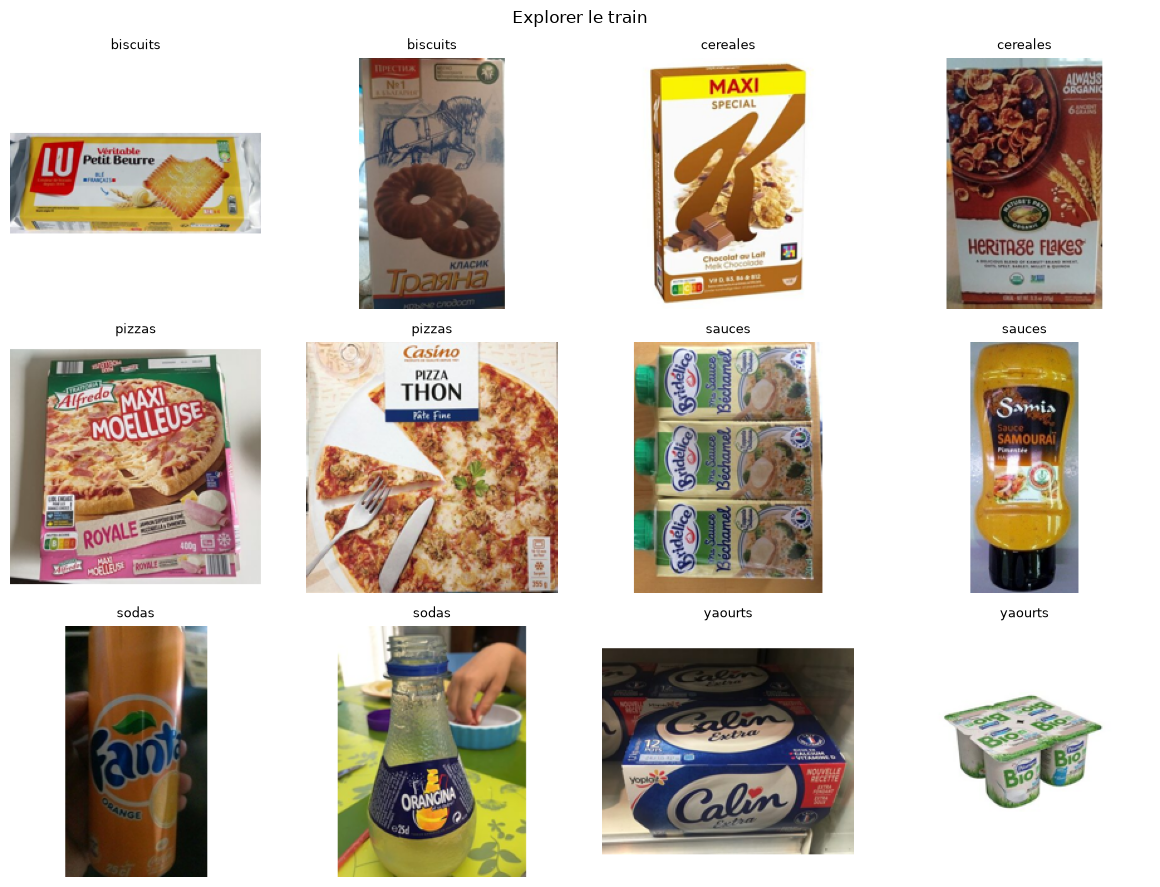

In [93]:
# TODO : sélectionner les lignes de partitions dont partition == "train".
part_train = partitions[partitions['partition'] == 'train']
# TODO : sélectionner quelques exemples de chaque rayon et les afficher.
exemples_train = (
    part_train.groupby("rayon", group_keys=False)
    .sample(n=2, random_state=GRAINE)
)
# TODO : noter les difficultés observées et les augmentations retenues.
afficher_planche(exemples_train, "Explorer le train")


## 6 — Préparer
Préparer des images RGB de taille commune. Pour le CNN, choisir une normalisation ; pour le transfert, utiliser le prétraitement attendu par le réseau choisi. Ne pas normaliser deux fois.

Choisir quelques augmentations pertinentes et les appliquer au train uniquement. Vérifier un lot avec `verifier_lot`.


Keras redimensionne déjà les images. Garder la même taille et les mêmes partitions pour les deux modèles. Si la taille change, recréer les datasets avec les mêmes chemins affectés.

Afficher quelques images augmentées pour vérifier que les produits restent reconnaissables.


In [95]:
def verifier_lot(images, cibles, taille=TAILLE_IMAGE):
    """Contrôler un lot brut avant normalisation."""
    assert images.shape.rank == 4 and tuple(images.shape[1:]) == (*taille, 3)
    assert cibles.shape.rank == 1 and images.shape[0] == cibles.shape[0]
    assert cibles.dtype.is_integer
    tf.debugging.assert_all_finite(images, "Pixels non finis")
    tf.debugging.assert_greater_equal(images, 0.0)
    tf.debugging.assert_less_equal(images, 255.0)
    tf.debugging.assert_greater_equal(cibles, 0)
    tf.debugging.assert_less(cibles, len(RAYONS))


def construire_pipelines(train_brut, validation_brute):
    """Préparer le chargement sans modifier les pixels ni les labels."""
    images, cibles = next(iter(train_brut))
    verifier_lot(images, cibles)

    train_prepare = train_brut.prefetch(tf.data.AUTOTUNE)
    validation_prepare = validation_brute.prefetch(tf.data.AUTOTUNE)

    description = {
        "taille_image": tuple(images.shape[1:3]),
        "mode_couleur": "RGB",
        "plage_pixels": [0, 255],
    }

    return train_prepare, validation_prepare, description

train_prepare, validation_prepare, description = construire_pipelines(
    train_dataset,
    validation_dataset,
)
print(description)

{'taille_image': (160, 160), 'mode_couleur': 'RGB', 'plage_pixels': [0, 255]}


## 7 — Annoncer le plancher et comparer
Calculer le score de validation d’une prédiction constante de la classe majoritaire du train. Ce score est le plancher auquel comparer les modèles.

Conserver un tableau simple : nom du modèle, configuration principale, accuracy et loss de validation. Choisir le modèle sur cette validation commune.


In [96]:
experiences = pd.DataFrame(columns=[
    "nom", "configuration", "accuracy_validation",
    "loss_validation", "observations",
])


def evaluer_plancher(cibles_train, cibles_validation):
    """Retourner la classe majoritaire du train et son accuracy validation."""
    classe_majoritaire = cibles_train.value_counts().idxmax()
    accuracy = float((cibles_validation == classe_majoritaire).mean())
    return classe_majoritaire, accuracy


classe_majoritaire, accuracy_plancher = evaluer_plancher(
    partitions.loc[partitions["partition"] == "train", "rayon"],
    partitions.loc[partitions["partition"] == "validation", "rayon"],
)

experiences.loc[len(experiences)] = {
    "nom": "Plancher majoritaire",
    "configuration": f"Prédire toujours {classe_majoritaire}",
    "accuracy_validation": accuracy_plancher,
    "loss_validation": np.nan,
    "observations": "Classe choisie uniquement sur le train.",
}

print(f"Classe majoritaire : {classe_majoritaire}")
print(f"Accuracy validation du plancher : {accuracy_plancher:.2%}")
display(experiences)


Classe majoritaire : sodas
Accuracy validation du plancher : 14.44%


,nom,configuration,accuracy_validation,loss_validation,observations
0,Plancher majoritaire,Prédire toujours sodas,0.144444,NaN,Classe choisie uniquement sur le train.


## 8A — CNN de zéro
Compl’ter `construire_cnn` avec un CNN simple initialisé sans poids préentraînés. Compiler avec une perte adaptée aux labels entiers, entraîner avec la validation et tracer les courbes. Reporter les scores dans le tableau de comparaison.


In [97]:
def tracer_historique(historique):
    """Afficher les pertes et accuracy présentes dans l’historique."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    for ax, nom in zip(axes, ("loss", "accuracy")):
        for cle in (nom, "val_" + nom):
            if cle in historique.history:
                ax.plot(historique.history[cle], label=cle)
        ax.set(xlabel="Époque (indice)", title=nom)
        if ax.lines:
            ax.legend()
    plt.tight_layout()
    plt.show()


def construire_cnn(taille_image, nombre_classes):
    """Construire un CNN simple sans poids préentraînés."""
    return tf.keras.Sequential([
        tf.keras.Input(shape=(*taille_image, 3)),

        # Actives uniquement pendant l'entraînement.
        tf.keras.layers.RandomRotation(0.03, seed=GRAINE),
        tf.keras.layers.RandomZoom(0.1, seed=GRAINE),

        # Pixels de [0, 255] vers [0, 1].
        tf.keras.layers.Rescaling(1.0 / 255),

        tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(nombre_classes, activation="softmax"),
    ], name="cnn_reference")

# TODO : compilation, propagation avant, essai court explicite.
# TODO : callbacks et régularisation justifiés, checkpoint, durée et bilan.


Model: "cnn_reference"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation                 │ (None, 160, 160, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 94,022 (367.27 KB)

 Trainable params: 94,022 (367.27 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15


c:\Users\Administrateur\Documents\NutriScope\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


132/132 ━━━━━━━━━━━━━━━━━━━━ 12s 84ms/step - accuracy: 0.2114 - loss: 1.7771 - val_accuracy: 0.2267 - val_loss: 1.7597
Epoch 2/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 10s 73ms/step - accuracy: 0.2567 - loss: 1.7339 - val_accuracy: 0.3022 - val_loss: 1.6934
Epoch 3/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 10s 74ms/step - accuracy: 0.3005 - loss: 1.6921 - val_accuracy: 0.3222 - val_loss: 1.6573
Epoch 4/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 10s 75ms/step - accuracy: 0.3243 - loss: 1.6452 - val_accuracy: 0.3667 - val_loss: 1.5863
Epoch 5/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 11s 86ms/step - accuracy: 0.3643 - loss: 1.5922 - val_accuracy: 0.3867 - val_loss: 1.5633
Epoch 6/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 11s 86ms/step - accuracy: 0.3552 - loss: 1.5751 - val_accuracy: 0.3844 - val_loss: 1.5255
Epoch 7/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 11s 83ms/step - accuracy: 0.3629 - loss: 1.5627 - val_accuracy: 0.3733 - val_loss: 1.5085
Epoch 8/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 11s 83ms/step - accuracy: 0.3929 - loss: 1.5284 - val_accurac

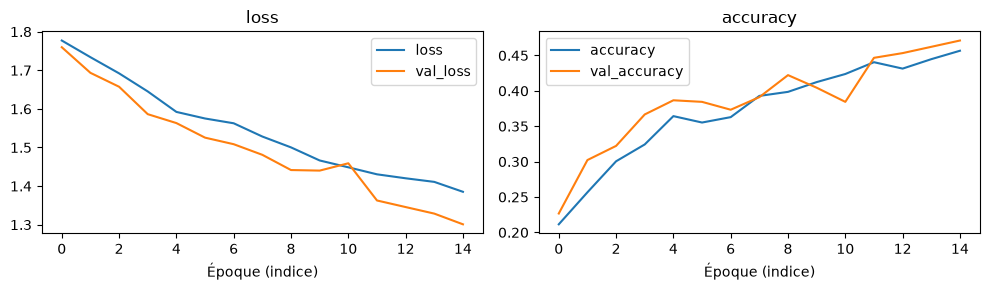

In [98]:
tf.keras.utils.set_random_seed(GRAINE)

cnn = construire_cnn(TAILLE_IMAGE, len(RAYONS))
cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
cnn.summary()

historique_cnn = cnn.fit(
    train_prepare,
    validation_data=validation_prepare,
    epochs=15,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True,
        ),
    ],
)

tracer_historique(historique_cnn)

In [99]:
loss_cnn, accuracy_cnn = cnn.evaluate(validation_prepare, verbose=0)

# Remplacer l'ancien résultat si cette cellule est réexécutée.
experiences = experiences.loc[experiences["nom"] != "CNN de zéro"].copy()

experiences.loc[len(experiences)] = {
    "nom": "CNN de zéro",
    "configuration": "Conv 32/64/128, rotation, zoom, dropout 0.3",
    "accuracy_validation": accuracy_cnn,
    "loss_validation": loss_cnn,
    "observations": "Meilleurs poids selon val_loss.",
}

display(experiences)

,nom,configuration,accuracy_validation,loss_validation,observations
0,Plancher majoritaire,Prédire toujours sodas,0.144444,NaN,Classe choisie uniquement sur le train.
1,CNN de zéro,"Conv 32/64/128, rotation, zoom, dropout 0.3",0.471111,1.301026,Meilleurs poids selon val_loss.


## 8B — Mod’le par transfert
Choisir un réseau préentraîné, par exemple MobileNetV2, geler sa base et entraîner une tête de classification sur les six rayons. Appliquer son prétraitement et les augmentations choisies, puis comparer au CNN sur la même validation.

Le fine-tuning est facultatif : le faire seulement si les résultats le justifient.


In [ ]:
def construire_transfert(taille_image, nombre_classes):
    """Retourner le modèle par transfert et sa base préentraînée gelée."""
    # TODO : charger une base préentraînée, par exemple avec weights="imagenet".
    # Le premier chargement peut télécharger les poids.
    # TODO : geler la base et ajouter une tête pour les six rayons.
    raise NotImplementedError("Construire le modèle par transfert.")

# TODO : compiler, entraîner et comparer au CNN sur la même validation.
# Facultatif : fine-tuning si les résultats le justifient.


## 8C — Choisir le modèle et le seuil
Choisir le modèle à partir des résultats de validation. Examiner quelques seuils de confiance sur cette validation : combien d’images sont acceptées et combien de ces prédictions sont incorrectes ? Justifier brièvement le seuil retenu pour répondre « je ne sais pas ».

Figer le modèle, son prétraitement et son seuil avant le test. La confiance maximale n’est pas une probabilité calibrée.


Collecter les cibles et les scores de validation dans une même boucle : le dataset est mélangé, deux parcours séparés pourraient les désaligner.


In [ ]:
def analyser_seuils(cibles, scores, seuils):
    """cibles : (N,) ; scores softmax : (N,6), finis et alignés.
    Retour : seuil, n_total, n_acceptees, n_erreurs_acceptees,
    couverture, taux_erreur_acceptees. Acceptation : confiance >= seuil.
    TODO : dimensions, bornes et absence d’acceptation.
    """
    raise NotImplementedError("Mesurer le compromis sur validation.")

# TODO : scores et cibles collectés dans une même boucle de validation.
# TODO : choisir et enregistrer checkpoint, préparation et seuil.
MODELE_FIGE = False


## 9 — Tester et analyser
évaluer une seule fois le modèle déjà choisi sur le test, sans augmentation et sans mélange. Conserver les prédictions pour calculer :

- l’accuracy globale et par rayon ;
- la matrice de confusion ;
- une planche des erreurs les plus parlantes, avec commentaires.

Tirer deux pistes d’amélioration de ces erreurs. Ne pas régler à nouveau le modèle ou le seuil sur le test.


L’accuracy par rayon est la proportion de bonnes prédictions parmi les images de ce vrai rayon. Dans la matrice de confusion : lignes = rayons réels, colonnes = rayons prédits.

Réutiliser les sorties du passage final pour les métriques et la planche d’erreurs, sans relancer l’inférence. Ne pas relancer la cellule de test après son évaluation.


In [ ]:
AUTORISER_TEST_FINAL = False
TEST_DEJA_EVALUE = False


def evaluer_test_final(modele, dossier_test, configuration):
    """Un passage déterministe ; retour aligné chemin/y_vrai/scores/y_predit.
    TODO : class_names=list(RAYONS), shuffle=False, sans validation_split,
    sans augmentation, avec préparation figée ; sauvegarder les sorties.
    """
    raise NotImplementedError("Implémenter le passage final.")

if AUTORISER_TEST_FINAL:
    assert MODELE_FIGE, "Figer modèle et seuil avant test."
    assert not TEST_DEJA_EVALUE, "Réutiliser les sorties sauvegardées."
    # TODO : appel unique, sauvegarde puis TEST_DEJA_EVALUE = True après succès.
    raise NotImplementedError("Compléter avant d’autoriser le test.")

# TODO : métriques, confusion et planches depuis les sorties sauvegardées.
# TODO : erreurs variées et confiantes ; commentaires en mots propres.


## 10 — Livrer la brique utilisable
Compl’ter `src/classifieur_images.py` : recevoir le chemin d’une photo et retourner le rayon et une confiance, ou à je ne sais pas à sous le seuil choisi. Réutiliser exactement le prétraitement et l’ordre des classes de l’entraînement.

Sauvegarder le modèle et ses métadonnées dans `models/`. Ajouter au moins un test pertinent de la brique.


**Métadonnées :** rayons ordonnés, taille d’image, prétraitement, seuil et score de test.

**Test minimal :** vérifier la décision autour du seuil avec des scores contrôlés. Une image absente ou illisible doit produire une erreur explicite.


In [ ]:
# TODO : impl’menter src/classifieur_images.py sans écraser src/classifier.py.
# TODO : sauvegarder le modèle et ses métadonnées dans models/.
# TODO : ajouter et exécuter au moins un test de la brique.


## Livrables demand’s par le README du TP17
- [ ] `notebooks/dl_images.ipynb` : travail complet et exécuté.
- [ ] `models/` : modèle sauvegard’ et métadonnées (rayons, taille, prétraitement, seuil, score de test).
- [ ] `src/classifieur_images.py` : prédiction depuis un chemin, confiance et abstention, avec au moins un test.
- [ ] `docs/ml/limites_images.md` : deux paragraphes sur les limites et deux pistes tirées de la planche d’erreurs.
- [ ] Crédit « contributeurs Open Food Facts », photos CC BY-SA ; images exclues de Git.
- [ ] Tag `v0.4` sur le commit final clôturant les TP14 à TP17, selon le workflow du dépôt.
